# Morphogen Gradients - Solving the Reaction Diffusion Equation
- Python program for the numerical solution of a partial differential equation (PDE) called the "Reaction Diffusion Equation":

$ \frac{\partial [Bcd](x,t)}{\partial t} = D \frac{\partial^{2} [Bcd](x,t)}{\partial x^{2}} - \frac{1}{\tau} [Bcd](x,t) $

- This PDE simulates the spatial and time evolution of Bicoid (morphogen) concentration inside a Drosophila (fluit fly) embryo.
- $D$ is the diffusion constant, $x$ is the spatial dimension along the anterior-posterior axis of the embryo, $t$ is time, $[Bcd](x,t)$ is concentration of Bicoid and $\tau$ is the lifetime of Bicoid molecular species.
- Solution method: FTCS method (Forward difference in Time; Central difference in Space)


Gradients of signalling molecules (called morphogens) are responsible for development of spatial patterns within multicellular organisms, because these molecules control gene expression. The spatial-temporal dynamics of the concentration of Bicoid ($[Bcd]$) morphogen inside a Drosophila embryo is determined by the reaction-diffusion equation.

For simplicity, only the single spatial dimension $x$ along the anterior-posterior axis of the embryo is considered [1,2].

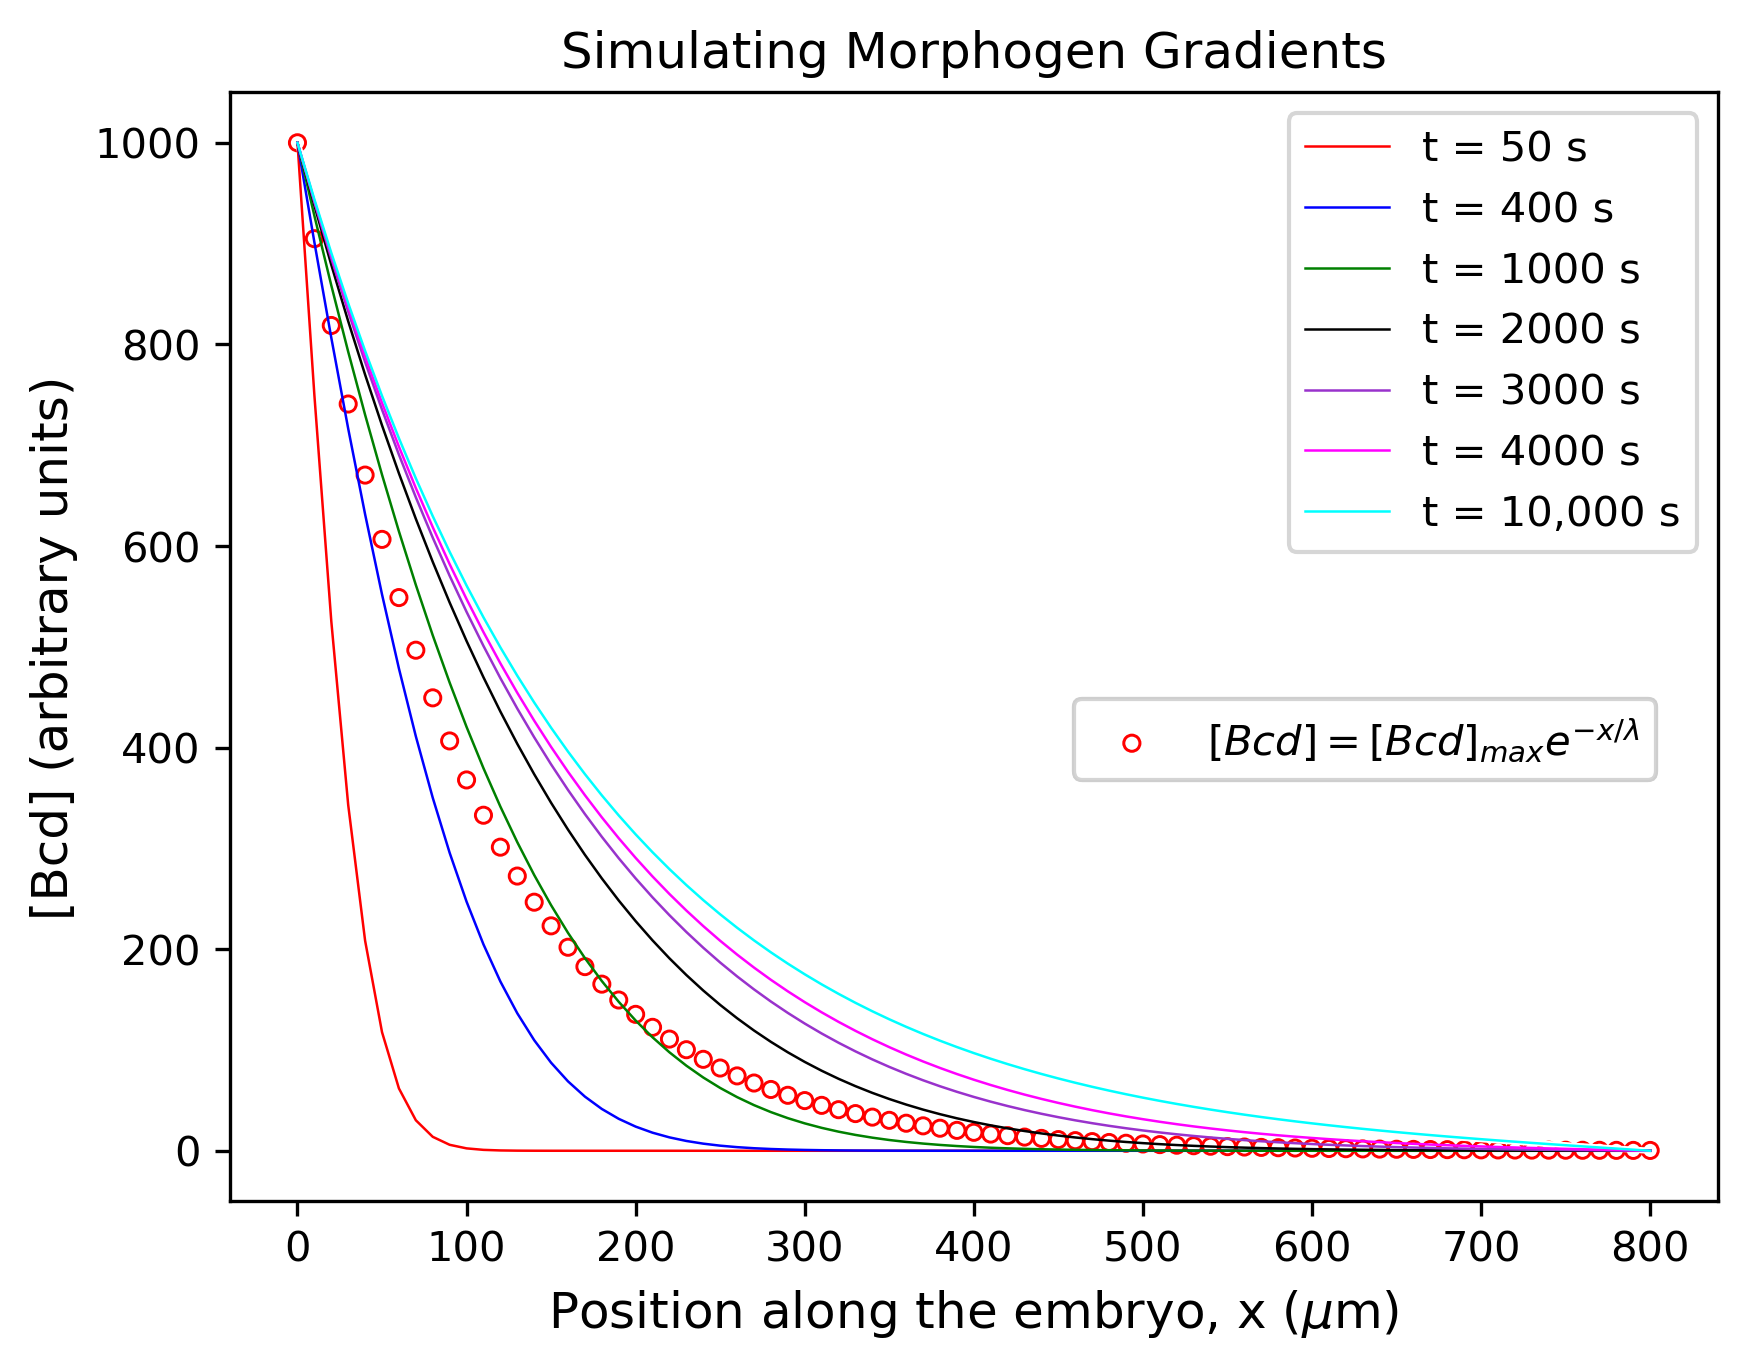

In [3]:
"""
@author: Apoorva Upadhyay
"""

from numpy import *
from matplotlib.pyplot import *
import numpy as np
import decimal
from decimal import Decimal

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi']=300 # highres display

from mpl_toolkits.mplot3d import Axes3D # import 3d plotting tool

import os

import re

import pandas as pd

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
#plt.rcParams['text.usetex'] = True

import math
import statistics

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

from matplotlib.animation import PillowWriter
from matplotlib.animation import FFMpegFileWriter
from matplotlib.animation import FFMpegWriter

import matplotlib.gridspec as gridspec



#######################################################################
# length in micro-meter
# time in seconds
# D = 5 (micro-meter)^2/second [experimentally determined?]
# tau = 3000 second [experimentally determined?]
# time range: 0 to 10,000 (seconds)
# embryo length, L = 5000 micro-meter
# maintain dx/dt ratio = 100?

# dicretise x axis
L = 800.0
#a = 1

x_min = 0.0
x_max = L
delta_x = 10.0
N = int((x_max - x_min)/(delta_x)+1)

x = np.linspace(x_min,x_max,N)

# dicretise time t "axis"
t_min = 0.0
t_max = 10000.0
delta_t = 0.1

#######################################
# IC: initial gaussian profile
def u_x_t0(x):
    
    #sigma_vals = 1.0
    #mu_vals = 1.0
    #u_x_t0 = (1/sigma_vals*np.sqrt(2*np.pi)) * np.exp(-(x-mu_vals)**2 / 2*sigma_vals**2)
    
    return np.zeros(N) #u_x_t0
#######################################
# constants
D = 10.0
tau = 3000.0
#######################################


    
u_x_t = np.zeros(N)
    
t = 0.0

def Tenperature(u_x_t0_init, D, delta_t, delta_x,tau):
    
    # index j runs over spatial points on x axis
    for j in range(0,len(u_x_t0_init)-1,1):
        
        u_x_t[j] = u_x_t0_init[j] + ( (((D)*delta_t)/(delta_x**2)) * (u_x_t0_init[j+1] + u_x_t0_init[j-1] - 2*u_x_t0_init[j]) ) - ((delta_t/tau)*u_x_t0_init[j])
        
        u_x_t[0] = 1000.0 # bc for t>0
        u_x_t[-1] = 0.0 # bc for t>0
        
    return u_x_t


#writer = FFMpegWriter(fps=15)

x_vals = []
y_vals = []

files_name = "{:03d}_ReactionDiffusion_Bicoid.jpg"

###############
fig = plt.figure()

#ax1 = plt.axes(xlim=(0.0,5.0), ylim=(0.0,3.0)) # setting the axes limits is important in animation
ax1 = plt.axes() # setting the axes limits is important in animation
#ax1 = plt.axes(xlim=(0.0,5000.0), ylim=(0.0,400.0)) # setting the axes limits is important in animation

###############

#fig, ax1 = plt.subplots(1,1, figsize=(8,4))
#l, = plt.plot([],[], 'r-')
#l, = ax1.plot([],[], 'r-')

#time_text = ax1.text(0.65, 0.95, '', fontsize=15, transform=ax1.transAxes, bbox=dict(facecolor='white',edgecolor='black'))

# create empty (line or scatter) objects and get control
# loop below will update the lines in each frame

#ax1.plot([],[],color='red') # line for gaussian 
ax1.plot([],[],color='white') # line for gaussian 
lines = ax1.get_lines() # get list of line objects in plot


#ax2 = inset_axes(ax1, width="80%", height="10%", loc=3, borderpad=1, bbox_to_anchor=(.0, 0.7, 1.0, 0.97), bbox_transform=ax1.transAxes)
#ax2.set_xlabel('',size=4)
#ax2.set_ylabel('',size=4)
#ax2.tick_params(axis='both', which='major', labelsize=5)



u_x_t0_init = u_x_t0(x) # IC: initial gaussian profile

#plt.plot(x, u_x_t0_init)

# BC:
u_x_t0_init[0] = 1000.0
u_x_t0_init[-1] = 0.0

#ax1.plot(x, u_x_t0_init, 'b--')

time = np.arange(t_min,t_max,delta_t)    

#ax2.imshow(np.atleast_2d(u_x_t0_init), cmap=plt.get_cmap('coolwarm'), extent=(-3, 3, 0, 1))

for k in range(0,len(time)-1,1):
    
    #enumerate(k)
    
    u_x_t = Tenperature(u_x_t0_init,D,delta_t,delta_x,tau)
    
    x_vals.append(x)
    y_vals.append(u_x_t)
    
    #lines[0].set_data(x_vals[k], y_vals[k]) # k here?
    """
    """    
    ######################
    # all on one plot
    
    if k == int(500):
        lines[0].set_data(x_vals[k], y_vals[k]) # k here?
        l1, = ax1.plot(x_vals[k], y_vals[k],'r-',linewidth=0.6,label='t = 50 s')
    
    if k == int(4000):
        lines[0].set_data(x_vals[k], y_vals[k]) # k here?
        l2, = ax1.plot(x_vals[k], y_vals[k],'b-',linewidth=0.6,label='t = 400 s')
        
    if k == int(10000):
        lines[0].set_data(x_vals[k], y_vals[k]) # k here?
        l3, = ax1.plot(x_vals[k], y_vals[k],'-',color='g',linewidth=0.6,label='t = 1000 s')
        
    if k == int(20000):
        lines[0].set_data(x_vals[k], y_vals[k]) # k here?
        l4, = ax1.plot(x_vals[k], y_vals[k],'k-',linewidth=0.6,label='t = 2000 s')
        
    if k == int(30000):
        lines[0].set_data(x_vals[k], y_vals[k]) # k here?
        l5, = ax1.plot(x_vals[k], y_vals[k],'-',color='darkorchid',linewidth=0.6,label='t = 3000 s')
        
    if k == int(40000):
        lines[0].set_data(x_vals[k], y_vals[k]) # k here?
        l6, = ax1.plot(x_vals[k], y_vals[k],'-',color='magenta',linewidth=0.6,label='t = 4000 s')
        
    #if k == int(99999):
        #lines[0].set_data(x_vals[k], y_vals[k]) # k here?
        #l7, = ax1.plot(x_vals[k], y_vals[k],'--',color='limegreen',linewidth=1.1,label='t = 10,000 s')
        

    
    
    #####################
    
    u_x_t0_init = u_x_t

ax1.plot(x_vals[-1], y_vals[-1],'-',color='cyan',linewidth=0.6,label='t = 10,000 s')

scat1 = ax1.scatter(x, 1000*np.exp(-x/100.0), marker='o', color='r', facecolors='none',s=15.0,linewidth=0.7)

legend1 = ax1.legend(prop={'size': 10},loc= "upper right")#,loc=(0.0,.25)) loc = "center right", loc= "upper right"
plt.gca().add_artist(legend1)

legend2 = ax1.legend([scat1],[r'$[Bcd] = [Bcd]_{max} e^{-x/\lambda}$'],loc=[0.567,0.38],prop={'size': 10})
plt.gca().add_artist(legend2)

ax1.set_ylabel(r'[Bcd] (arbitrary units)', fontsize=12)
ax1.set_xlabel(r'Position along the embryo, x ($\mu$m)',fontsize=12)

#plt.savefig('ReactionDiffusion_Bicoid_ALL.pdf',bbox_inches = 'tight', dpi=200)

plt.title('Simulating Morphogen Gradients')

plt.show()

Numerical solution of the reaction-diffusion equation for the Bicoid concentration [Bcd] as a function of spatial position along the Drosophila embryo $(x)$ and time $(t)$ is shown in the figure above. Simulation results are shown with solid lines. Experimental measurements are reproduced from references [1,2] and are shown in red circles. The experimentally determined value of $\lambda$ = 100 $\mu m$ is used [2]. The simulation is run for a maximum time of t = 10,000 seconds.
    
The initial condition used is $[Bcd](x, t = 0) = 0$ (arbitrary units). The boundary conditions used are (arbitrary units): $[Bcd](x = 0, t) = 1000$, $[Bcd](x = L, t) = 0$. The first boundary condition at $x = 0$ indicates a source of Bicoid being produced at the anterior end of the embryo. The second boundary condition at $x = L$ indicates no Bicoid leaving the embryo at the posterior end. The length of the Drosophila embryo is chosen to be $L = 800$ $\mu m$.  The constants D and $\tau$ are chosen to have experimentally determined values of 10 $\mu m^{2}$ and 3000 s respectively [1,2]. The simulation results as visualised in the figure above show the calculations to be sufficiently converged, as illustrated by $[Bcd] (x)$ profiles converging as time evolves. The calculations and measurements of Bicoid concentration show good (qualitative) agreement, although further analysis will be performed to quantify this.

The model currently assumes uniform diffusion and degradation of Bicoid within the cell. The model can be improved by considering different degradation and diffusion rates within different cell organelles such as nuclei etc. Furthermore, reaction-diffusion models are most effective at simulating observations at molecular length scales, and different transport mechanisms would need to be considered to model biological systems at large length scales [2].



References:

[1] Gregor, T., Bialek, W., Van Steveninck, R. R. D. R., Tank, D. W., & Wieschaus, E. F. (2005). Diffusion and scaling during early embryonic pattern formation. Proceedings of the National Academy of Sciences, 102(51), 18403-18407.

[2] Phillips, R., Kondev, J., Theriot, J., Garcia, H.G. (2013). Physical Biology of the Cell, 2nd ed., CRC Press, Taylor & Francis Group
